# The seabed at seven candidate mouths, 1850–1887

This notebook fits the same seabed model to every candidate mouth on the Malabar coast that has a measured
19th-century survey, and compares them on the same terms.

**What it is for.** Under the turnaround reading of the Periplus, a large ship lay off a river mouth and was
worked by boats. That makes three properties of each mouth worth comparing:

* how far out a loaded ship would have found anchoring water;
* what the bar or approach would admit;
* how steeply the shelf falls away.

**What it is not.** These are seabeds of the 1850s and 1880s, not of AD 50. The
comparison ranks the mouths as they were surveyed. It does not locate a port, and it is one input to the
later blending step.

**The sites.** All soundings were read by eye and checked a second time (`scripts/transcriptions/`).

| Site | Port | Chart | Survey | Note |
|---|---|---|---|---|
| Kodungallur | Muziris | BA 749 | 1851–3 | the pilot site, from `bathymetry_1857.ipynb` |
| Ponnani | Tyndis | BA 749 | 1851–3 | river mouth |
| Tanur | Tyndis | BA 749 | 1851–3 | open beach, no entrance |
| Beypore | Tyndis | chart 64 | 1887 | river mouth; Chaliyam on the south side |
| Koyilandy | Tyndis | chart 64 | 1887 | open shore with an inshore mud shoal |
| Kollam | Nelkynda, Bakarē | BA 750 | 1850–2 | the Ashtamudi entrance (Neendakara) and Thangassery |
| Purakkad | Nelkynda, Bakarē | BA 750 | 1850–2 | open shore with a charted mud-bank anchorage |

**The model** is model F (`scripts/seabed_model.R`): the near-shore model validated in
`validation_bathymetry.ipynb` against two fully surveyed inlets. It has three parts:

* a smooth seabed field;
* a fine-scale field whose spread is largest at a river mouth and along the shore;
* shoreline anchors and a beach-face term.

The fine-scale profile was set on San Luis Pass and tested, unchanged, on Pass Cavallo. At sites with no
river or lagoon entrance, the mouth part of that profile is switched off. The observation noise is fixed
at 0.4 m.

**Comparability, and what differs between sites.**

1. **Survey date and scale.** Beypore and Koyilandy come from an 1887 survey at about three times the
   scale of Selby's 1850s sheets. They are denser close in, and they come a generation later.
2. **Datum.** Chart 64 states its datum: lowest low water springs, with a spring rise of 5 ft. Selby's sheets
   do not, so low water springs is assumed there, with a spring rise of 3 ft. A wrong datum shifts every
   depth on a sheet by up to about a metre, but it does not change the ranking within a sheet.
3. **Coastline.** The coasts were traced from the charts to about ±200 m on Selby's sheets and ±60 m on chart
   64 (`scripts/sounding_sites.py`).
4. **Controlling depths are lower bounds.** The validation showed that a survey without a line of
   soundings down the channel reads a pass's controlling depth 1–2 m too shallow, and none of these
   surveys has such a line. Anchorage distances and shelf depths are pointwise quantities. The
   validation found those calibrated.

In [1]:
import sys, os, json, pathlib, time
os.environ.setdefault("R_HOME", "/Library/Frameworks/R.framework/Resources")
os.environ.setdefault("RPY2_CFFI_MODE", "ABI")
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from scipy import ndimage

ROOT = pathlib.Path.cwd().resolve().parents[1]
SCRIPTS = ROOT / "quantitative/coastline/scripts"; sys.path.insert(0, str(SCRIPTS))
import seabed_inputs
SND = ROOT / "quantitative/coastline/data/soundings"
FIGS = ROOT / "quantitative/coastline/figures"
SITES = ["kodungallur", "ponnani", "tanur", "beypore", "koyilandy", "kollam", "purakkad"]
# Refit only sites without posterior draws, or all of them after a transcription changes
FORCE_REFIT = False
FS_R, MODEL_R = str(SCRIPTS / "fine_scale.R"), str(SCRIPTS / "seabed_model.R")
FATHOM = 1.8288
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
T0 = time.time()

## 1. Inputs

`scripts/seabed_inputs.py` writes each site's model inputs from its transcription and its traced coast.
These are:

* the soundings on the sea side of the coast;
* shoreline anchors every 50 m;
* land and unsounded backwater;
* a 100 m prediction grid.

At a river mouth, a small circle is cut out of the land so that the entrance and its soundings stay in
the model. Soundings landward of the coast are left out: the backwater arm behind Quilon, and the
Beypore river channel above its mouth. That is the treatment the unsounded lagoon got at Kodungallur.

In [2]:
meta = pd.DataFrame([seabed_inputs.build_kodungallur() if s == "kodungallur" else seabed_inputs.build(s) for s in SITES]).set_index("site")
print(meta[["port", "sheet", "surveyed", "soundings_used", "soundings_excluded_landward", "shore_anchors", "grid_cells", "water_km2"]].to_string())

/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(
/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(
/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(
/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(


/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(
/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(
/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(
/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(
/Users/vivek

                          port  sheet                                 surveyed  soundings_used  soundings_excluded_landward  shore_anchors  grid_cells  water_km2
site                                                                                                                                                             
kodungallur            Muziris  BA749                                   1851-3             157                            0           1169        6565       64.9
ponnani                 Tyndis  BA749                                   1851-3             390                            0            408       25003      248.9
tanur                   Tyndis  BA749                                   1851-3             386                            0            383       22114      220.1
beypore                 Tyndis   BA64                                     1887             307                           21            155        4508       45.0
koyilandy               Tynd

/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(
/Users/vivek/Documents/Thesis/Code/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:948: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(


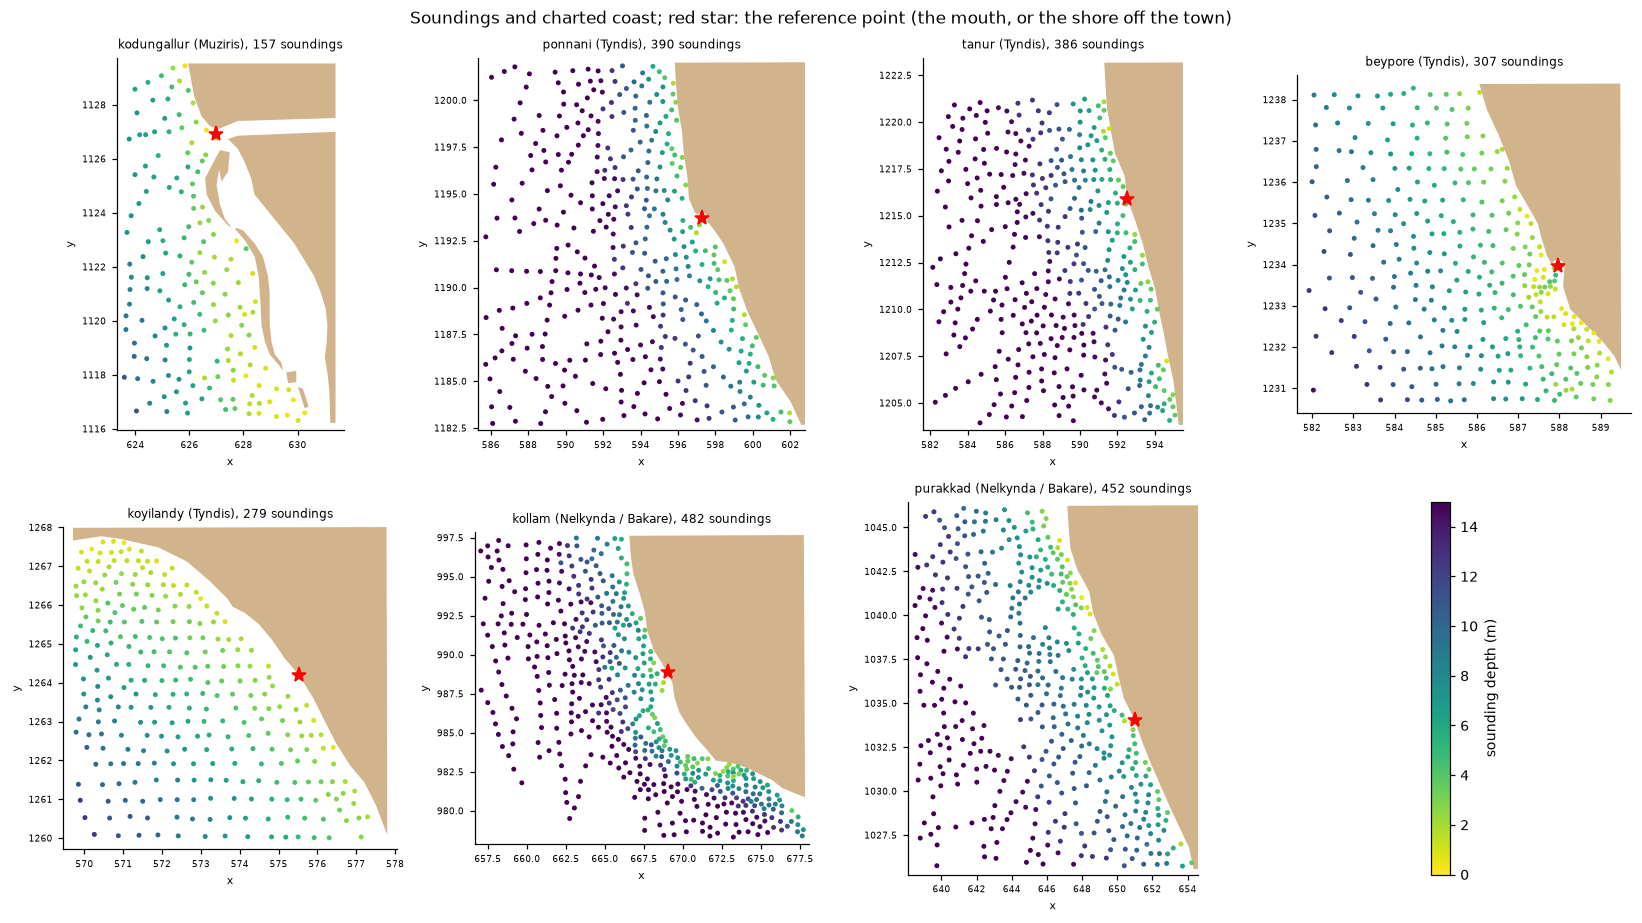

In [3]:
def load(site):
    D = SND / site / "model"
    return dict(snd=pd.read_csv(D / "soundings.csv"), grid=pd.read_csv(D / "grid.csv"),
                land=gpd.read_file(D / "land.geojson").geometry[0], meta=json.loads((D / "site.json").read_text()))

fig, axes = plt.subplots(2, 4, figsize=(15, 8.5)); axes = axes.ravel()
for a, s in zip(axes, SITES):
    d = load(s); g = d["grid"]
    gpd.GeoSeries([d["land"]]).plot(ax=a, color="tan")
    sc = a.scatter(d["snd"].x_km, d["snd"].y_km, c=d["snd"].depth_m, s=5, cmap="viridis_r", vmin=0, vmax=15)
    r = d["meta"]["ref"]; a.plot(*r, "r*", ms=10)
    a.set_xlim(g.x_km.min() - .3, g.x_km.max() + .3); a.set_ylim(g.y_km.min() - .3, g.y_km.max() + .3)
    a.set_aspect("equal"); a.set_title(f"{s} ({d['meta']['port']}), {len(d['snd'])} soundings", fontsize=8)
    a.tick_params(labelsize=6)
axes[-1].axis("off"); plt.colorbar(sc, ax=axes[-1], label="sounding depth (m)", fraction=.6)
fig.suptitle("Soundings and charted coast; red star: the reference point (the mouth, or the shore off the town)")
plt.tight_layout(); fig.savefig(FIGS / "mouths_soundings.png", dpi=140); plt.show()

## 2. Fitting model F at each mouth

Fits take between ten seconds and six minutes each. Draws are saved in `data/soundings/<site>/model/samples.bin`,
which is gitignored. A site is refitted only if it has no draws yet, or if `FORCE_REFIT` is set. Set it after
any change to a transcription or a traced coast.

In [4]:
TO_FIT = [str(SND / s / "model") for s in SITES if FORCE_REFIT or not (SND / s / "model" / "samples.bin").exists()]
print("fitting:", [pathlib.Path(d).parent.name for d in TO_FIT] or "none, using saved draws")

fitting: ['kodungallur']


In [5]:
%load_ext rpy2.ipython

In [6]:
%%R -i TO_FIT -i FS_R -i MODEL_R
.libPaths(c(path.expand("~/Library/R/arm64/4.5/library"), .libPaths()))
source(MODEL_R); inla.setOption(num.threads = "4:1"); set.seed(2026)
for (d in TO_FIT) invisible(seabed_fit_site(d, FS_R))

In [7]:
fits = pd.DataFrame([dict(site=s, mesh_nodes=f["mesh_nodes"], b0=f["fixed"]["b0"]["mean"], slope_m_per_km=f["fixed"]["dist"]["mean"],
                          beach_step_m=f["fixed"]["beach"]["mean"], field_range_km=f["hyper"]["Range for field"],
                          field_sd_m=f["hyper"]["Stdev for field"], fit_seconds=f["seconds"])
                     for s in SITES for f in [json.loads((SND / s / "model" / "fit.json").read_text())]]).set_index("site")
print(fits.round(2).to_string())

             mesh_nodes    b0  slope_m_per_km  beach_step_m  field_range_km  field_sd_m  fit_seconds
site                                                                                                
kodungallur        9221 -0.40            1.55          1.98            4.16        0.88           16
ponnani           11013 -0.26            1.87          3.34            7.78        2.15           70
tanur             10719  0.35            1.98          3.95            3.80        1.20           32
beypore            4086 -0.30            1.90          2.35           10.56        0.50           53
koyilandy          4526 -0.44            1.75          1.35            5.16        0.36           12
kollam            12256 -0.55            2.93          4.53            3.06        2.75           13
purakkad          11523 -0.38            1.68          2.42            5.00        1.44           11


**Reading the fixed effects.** The intercept is the depth at the charted coast, and it sits near the
anchors' −0.46 m. The slope is the shelf gradient beyond the beach face. The beach step is the drop
across the first few hundred metres. These describe each coast's profile. Each is estimated with the
spatial field alongside, so it is a summary, not a test.

## 3. The reconstructed seabeds

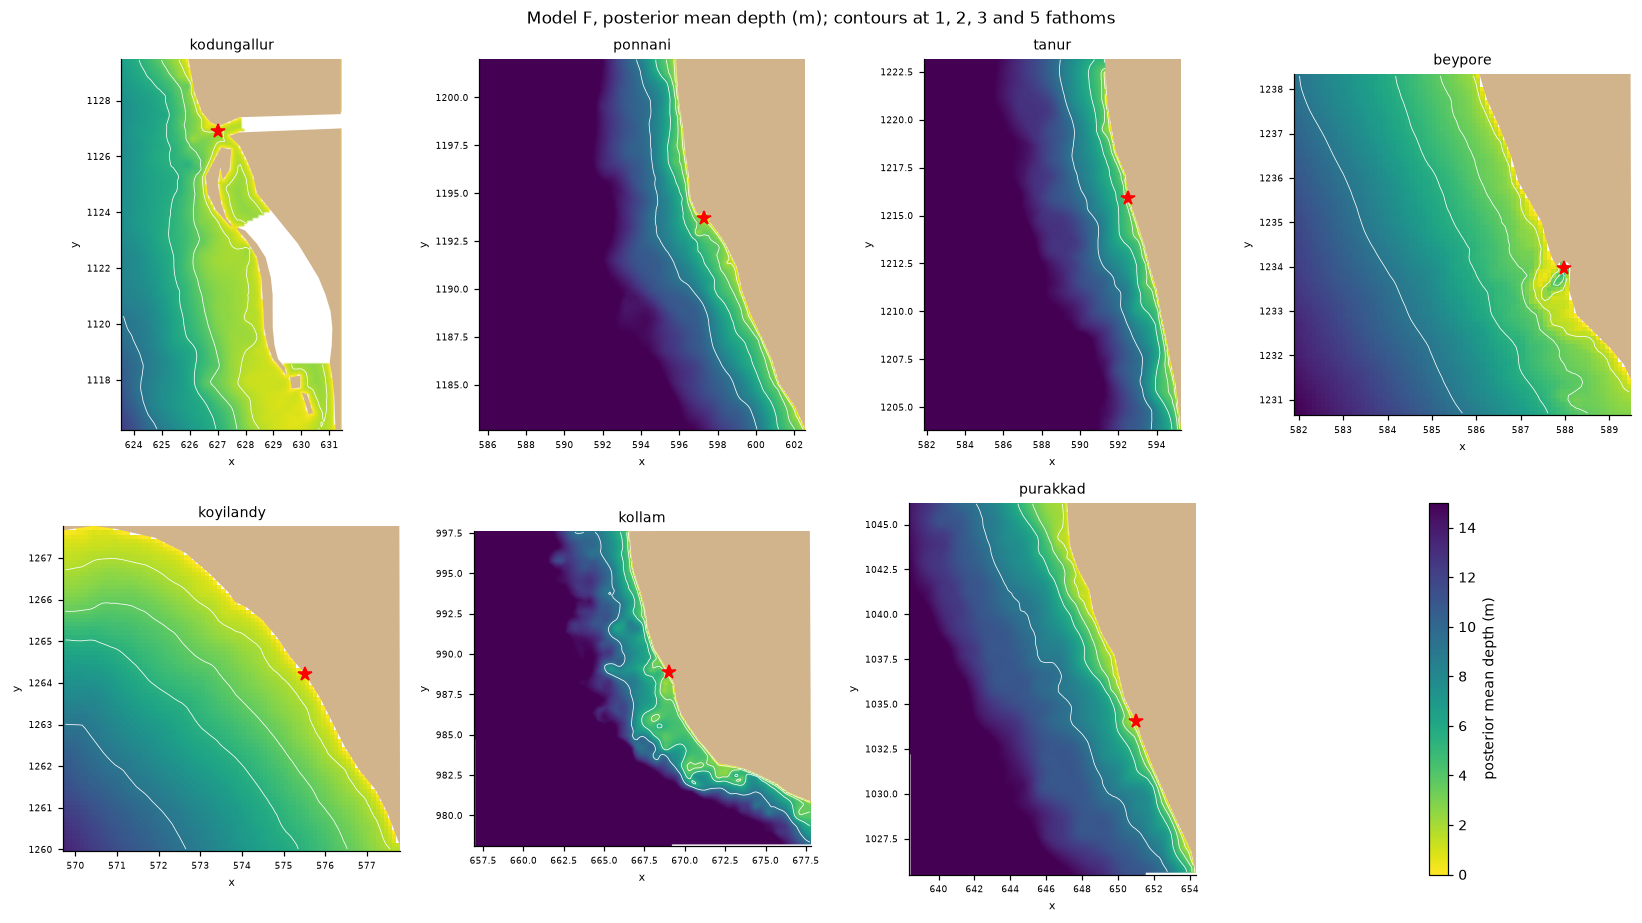

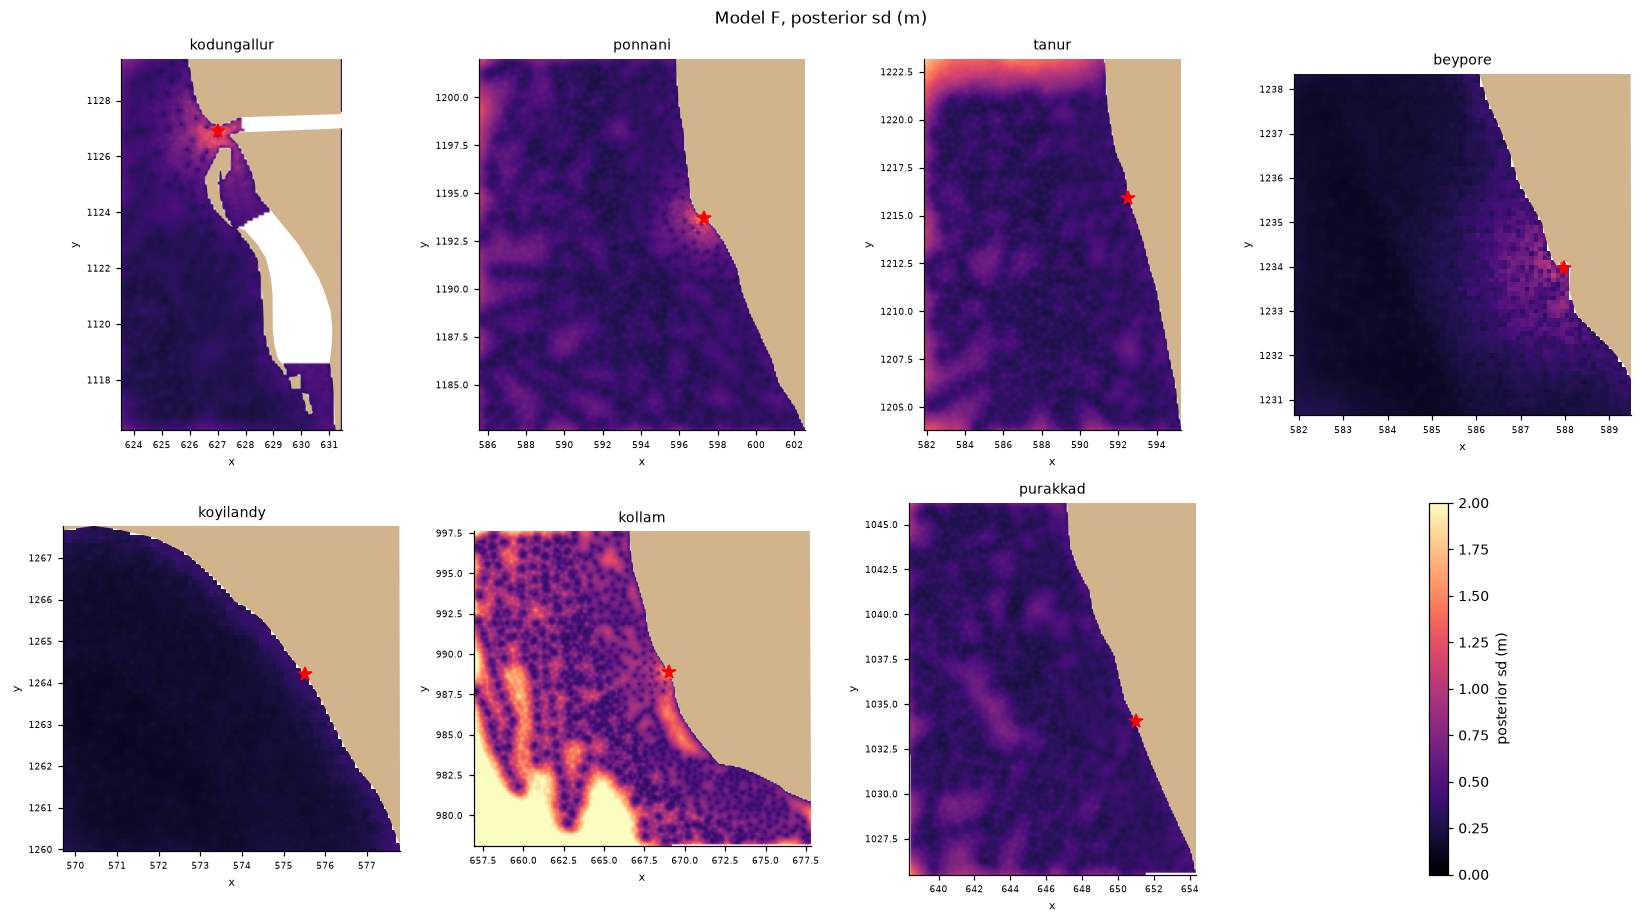

In [8]:
post = {}
for s in SITES:
    d = load(s); g = d["grid"]
    S = np.fromfile(SND / s / "model" / "samples.bin", dtype=np.float32).reshape(len(g), -1)
    post[s] = dict(d, S=S, mean=S.mean(1), sd=S.std(1))

def gridded(g, v, step=0.1):
    i = np.round((g.x_km - g.x_km.min()) / step).astype(int); j = np.round((g.y_km - g.y_km.min()) / step).astype(int)
    A = np.full((j.max() + 1, i.max() + 1), np.nan); A[j, i] = v
    return A, [g.x_km.min() - step / 2, g.x_km.max() + step / 2, g.y_km.min() - step / 2, g.y_km.max() + step / 2]

for what, cmap, lim, lab, fn in [("mean", "viridis_r", (0, 15), "posterior mean depth (m)", "mouths_seabed_mean.png"),
                                  ("sd", "magma", (0, 2), "posterior sd (m)", "mouths_seabed_sd.png")]:
    fig, axes = plt.subplots(2, 4, figsize=(15, 8.5)); axes = axes.ravel()
    for a, s in zip(axes, SITES):
        p = post[s]; A, ext = gridded(p["grid"], p[what])
        im = a.imshow(A, origin="lower", extent=ext, cmap=cmap, vmin=lim[0], vmax=lim[1])
        if what == "mean":
            a.contour(A, levels=[FATHOM, 2 * FATHOM, 3 * FATHOM, 5 * FATHOM], colors="w", linewidths=.5, origin="lower", extent=ext)
        gpd.GeoSeries([p["land"]]).plot(ax=a, color="tan"); a.plot(*p["meta"]["ref"], "r*", ms=9)
        a.set_xlim(ext[0], ext[1]); a.set_ylim(ext[2], ext[3]); a.set_aspect("equal"); a.set_title(s, fontsize=9); a.tick_params(labelsize=6)
    axes[-1].axis("off"); plt.colorbar(im, ax=axes[-1], label=lab, fraction=.6)
    fig.suptitle(f"Model F, {lab}" + ("; contours at 1, 2, 3 and 5 fathoms" if what == "mean" else ""))
    plt.tight_layout(); fig.savefig(FIGS / fn, dpi=140); plt.show()

## 4. Comparing the mouths

Three measures are computed from the joint posterior draws. Each is measured from the reference point,
which is the mouth where there is one and otherwise the shore opposite the candidate town.

* **Shelf depth.** The posterior mean depth at 1, 2 and 3 km from the coast, within 3 km alongshore of the
  reference point.
* **Anchorage distance.** For a ship of draught *d* needing *d* + 0.5 m of water: walk seaward from the
  reference point along a 300 m-wide corridor towards the deepest water 4 km out. Record the first distance
  beyond which the probability of enough water stays at least 0.9, and, for comparison, at least 0.5.
  Draughts of 2, 3 and 4 m span the range used elsewhere in the project for a Roman merchant ship.
  - **Why not the nearest deep cell in each draw?** That was tried first and rejected. Near a mouth the
    fine-scale field allows deep pockets close in, and the minimum over thousands of cells always finds one.
    The result was a spuriously short distance at every site.
* **Bar depth (mouths only).** The deepest water by which a boat can get from the entrance (the charted gap
  between the spits) to 4 km offshore, computed in every draw. **It is a lower bound**, because none of these
  surveys sounded a line down the channel. The table also gives how many soundings lie within 500 m of the
  entrance. Where there are none, the entrance depth comes from the model's profile, not from a measurement.
  Where fewer than two soundings lie within 500 m, the entrance was not sounded and no bar depth is given.
  At an open beach there is no bar to cross, so the measure is not given.
  - The validation started from the deepest cell within 500 m of the pass. That was tried here and
    rejected: on a 1:146,000 chart, 500 m reaches past the bar into deeper water, and the path then never
    crosses the bar.

In [9]:
def neighbours(g, step=0.1):
    i = np.round((g.x_km - g.x_km.min()) / step).astype(int).values; j = np.round((g.y_km - g.y_km.min()) / step).astype(int).values
    return i, j

def bar_depth(depth, i, j, a, b, iters=16):
    G = np.full((j.max() + 1, i.max() + 1), -99.0); G[j, i] = depth
    lo, hi = -5.0, float(min(depth[a], depth[b]))
    for _ in range(iters):
        m = (lo + hi) / 2; lab, _ = ndimage.label(G > m, structure=np.ones((3, 3)))
        lo, hi = (m, hi) if lab[j[a], i[a]] and lab[j[a], i[a]] == lab[j[b], i[b]] else (lo, m)
    return lo

def first_sure(dist, p, level):
    # first distance beyond which p stays >= level (nan if never)
    ok = p >= level
    if not ok.any(): return np.nan
    tail = np.flip(np.logical_and.accumulate(np.flip(ok)))      # True from the last False onwards
    return dist[tail][0] if tail.any() else np.nan

rows, corridors = [], {}
for s in SITES:
    p = post[s]; g = p["grid"]; S = p["S"]; ref = np.array(p["meta"]["ref"]); xy = g[["x_km", "y_km"]].values
    near = g.d_ref_km < 3
    row = dict(site=s, port=p["meta"]["port"], survey=p["meta"]["surveyed"][:6])
    for dk in [1, 2, 3]:
        band = (near & (np.abs(g.dist_km - dk) < 0.15)).values
        row[f"shelf depth at {dk} km (m)"] = p["mean"][band].mean() if band.any() else np.nan
    # corridor seaward from ref towards the deepest cell 3.5-4.5 km out
    ring = np.where((g.d_ref_km > 3.5) & (g.d_ref_km < 4.5))[0]; tgt = xy[ring[np.argmax(p["mean"][ring])]]
    u = (tgt - ref) / np.hypot(*(tgt - ref)); along = (xy - ref) @ u; across = np.abs((xy - ref) @ np.array([-u[1], u[0]]))
    cor = np.where((across < 0.15) & (along > 0) & (along < 4.5))[0]; cor = cor[np.argsort(along[cor])]
    corridors[s] = (along[cor], S[cor])
    for draught in [2, 3, 4]:
        need = draught + 0.5; pr = (S[cor] > need).mean(1)
        row[f"anchorage, {draught} m draught: P>=0.9 (km)"] = first_sure(along[cor], pr, 0.9)
        row[f"anchorage, {draught} m draught: P>=0.5 (km)"] = first_sure(along[cor], pr, 0.5)
    if p["meta"]["mouth"] is not None:
        i, j = neighbours(g); m = np.array(p["meta"]["mouth"])
        a = int(np.argmin(np.hypot(*(xy - m).T))); b = int(ring[np.argmax(p["mean"][ring])])
        row["soundings within 500 m of entrance"] = int((np.hypot(p["snd"].x_km - m[0], p["snd"].y_km - m[1]) < 0.5).sum())
        if row["soundings within 500 m of entrance"] >= 2:      # otherwise the entrance depth is the model's guess
            bd = np.array([bar_depth(S[:, k], i, j, a, b) for k in range(0, S.shape[1], 2)])
            row["bar depth, lower bound (m)"] = np.median(bd); row["_bar_lo"], row["_bar_hi"] = np.percentile(bd, [5, 95])
            row["entrance depth, mean (m)"] = p["mean"][a]
        else:
            row["bar depth, lower bound (m)"] = np.nan; row["entrance depth, mean (m)"] = np.nan
            row["note"] = "entrance not sounded: no bar estimate"
    rows.append(row)
cmp_ = pd.DataFrame(rows).set_index("site")
show = cmp_[[c for c in cmp_.columns if not c.startswith("_")]]
with pd.option_context("display.width", 250):
    print(show.round(1).T.to_string())
cmp_.to_csv(SND / "mouths_comparison.csv")

site                                kodungallur                                ponnani   tanur beypore koyilandy                                 kollam           purakkad
port                                    Muziris                                 Tyndis  Tyndis  Tyndis    Tyndis                      Nelkynda / Bakare  Nelkynda / Bakare
survey                                   1851-3                                 1851-3  1851-3    1887      1887                                 1850-2             1850-2
shelf depth at 1 km (m)                     4.7                                    5.7     6.1     3.9       2.8                                    5.3                5.7
shelf depth at 2 km (m)                     6.3                                    8.3     8.6     6.1       4.6                                    7.5                7.7
shelf depth at 3 km (m)                     NaN                                    9.7    11.0     NaN       5.9                                 

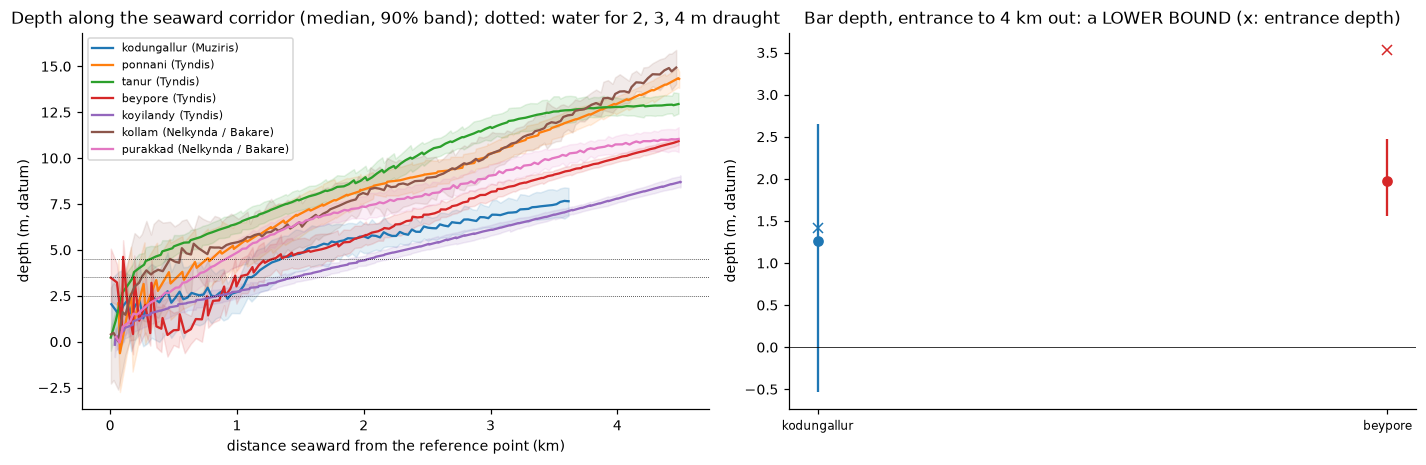

notebook run time 0.4 min


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
cols = dict(zip(SITES, plt.cm.tab10(np.arange(len(SITES)))))
for s in SITES:
    along, Sc = corridors[s]
    ax[0].plot(along, np.median(Sc, 1), color=cols[s], label=f"{s} ({cmp_.loc[s, 'port']})")
    ax[0].fill_between(along, np.percentile(Sc, 5, 1), np.percentile(Sc, 95, 1), color=cols[s], alpha=.12)
for d in (2.5, 3.5, 4.5):
    ax[0].axhline(d, color="k", lw=.5, ls=":")
ax[0].set_xlabel("distance seaward from the reference point (km)"); ax[0].set_ylabel("depth (m, datum)")
ax[0].set_title("Depth along the seaward corridor (median, 90% band); dotted: water for 2, 3, 4 m draught"); ax[0].legend(fontsize=7)
mouths = [s for s in SITES if "bar depth, lower bound (m)" in cmp_.columns and pd.notna(cmp_.loc[s, "bar depth, lower bound (m)"])]
for k, s in enumerate(mouths):
    r = cmp_.loc[s]; v = r["bar depth, lower bound (m)"]
    ax[1].errorbar(k, v, yerr=[[v - r["_bar_lo"]], [r["_bar_hi"] - v]], fmt="o", color=cols[s])
    ax[1].plot(k, r["entrance depth, mean (m)"], "x", color=cols[s])
ax[1].set_xticks(range(len(mouths))); ax[1].set_xticklabels(mouths, fontsize=8)
ax[1].set_ylabel("depth (m, datum)"); ax[1].set_title("Bar depth, entrance to 4 km out: a LOWER BOUND (x: entrance depth)")
ax[1].axhline(0, color="k", lw=.5)
plt.tight_layout(); fig.savefig(FIGS / "mouths_comparison.png", dpi=140); plt.show()
print(f"notebook run time {(time.time() - T0) / 60:.1f} min")

## 5. Reading the comparison

These points hold whatever the numbers come out to be. The numbers themselves are in the tables above,
and are written up in `quantitative/coastline/notes.md`.

1. **Anchorage distance is the more robust measure.** It depends on the shelf, which every survey samples densely
   and which the validation found well calibrated. It answers a question the turnaround reading asks
   directly: how far the boats had to go.
2. **Approach depths are floors.** A deeper channel through a bar can exist between soundings and would not
   show. A low approach depth is therefore weak evidence that a mouth was shallow, and a high one is strong
   evidence that it was deep.
3. **The 1887 sites are not strictly comparable with the 1850s ones.** They come a generation later and at
   three times the scale. Rank within a survey before ranking across surveys.
4. **None of this is the first century.** Coastlines on this coast have moved by kilometres since the Early
   Historic period, and bars at monsoon river mouths move from season to season. The ranking describes the
   mouths as surveyed. It becomes evidence about AD 50 only through the coastline and sea-level work.